In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


# Zadanie 1

In [61]:
df = sns.load_dataset("mpg")
print(df.shape)
print(df.isna().sum())
print(df.duplicated().sum())
print(df.isna().mean().round(2))

(398, 9)
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64
0
mpg             0.00
cylinders       0.00
displacement    0.00
horsepower      0.02
weight          0.00
acceleration    0.00
model_year      0.00
origin          0.00
name            0.00
dtype: float64


In [12]:
df["1_100km"] = 235.215/df["mpg"]
print(df["1_100km"].mean().round(2))
print(df["1_100km"].min().round(2))
print(df["1_100km"].max().round(2))

11.21
5.05
26.14


In [17]:
summary = df.groupby(["origin"]).agg(liczebnosc=("name", "count"), srednia=("1_100km", "mean"), mediana_mocy=("horsepower", "median"), masa=("weight", "max")).sort_values(by="srednia")

summary

,liczebnosc,srednia,mediana_mocy,masa
origin,,,,
japan,79,8.063175,75.0,2930
europe,70,8.911678,76.5,3820
usa,249,12.859421,105.0,5140


In [23]:
summary = df[(df["model_year"] >= 76) & (df["cylinders"] != 5)].groupby(["origin", "cylinders"]).agg(n=("origin", "count"), mean_hp = ("horsepower", "mean")).sort_values(by="mean_hp", ascending=False)

summary

n     mean_hp
origin cylinders                
usa    8          34  140.382353
japan  6           5  114.600000
europe 6           4  113.500000
japan  3           2  105.000000
usa    6          36  101.444444
       4          55   81.094340
europe 4          30   74.892857
japan  4          47   72.446809

In [24]:
summary = df[(df["model_year"] >= 76) & (df["cylinders"] != 5)].groupby(["origin", "cylinders"]).agg(n=("horsepower", "count"), mean_hp = ("horsepower", "mean")).sort_values(by="mean_hp", ascending=False)

summary

n     mean_hp
origin cylinders                
usa    8          34  140.382353
japan  6           5  114.600000
europe 6           4  113.500000
japan  3           2  105.000000
usa    6          36  101.444444
       4          53   81.094340
europe 4          28   74.892857
japan  4          47   72.446809

In [29]:
mediana = df["1_100km"].median()

df["eco"] = np.where(df["1_100km"] < mediana, "tak", "nie")

(df["eco"].value_counts()/df["eco"].count()).round(1)

eco
nie    0.5
tak    0.5
Name: count, dtype: float64

# Zadanie 2

In [91]:
import pandas as pd

mpg = sns.load_dataset("mpg")

# Kopia zbioru mpg
mpg_bledy = mpg.copy()

# 1. Brakujące wartości
mpg_bledy.loc[0:4, "manufacturer"] = None
mpg_bledy.loc[9:14, "cty"] = None

# 2. Duplikaty rekordów
mpg_bledy = pd.concat([mpg_bledy, mpg_bledy.iloc[:10]], ignore_index=True)

# 3. Błędne wartości i wartości odstające
mpg_bledy.loc[19, "hwy"] = 999
mpg_bledy.loc[29, "displ"] = -5

# 4. Błędne kategorie
mpg_bledy.loc[39, "class"] = "unknown"
mpg_bledy.loc[49, "drv"] = "X"

# 5. Błędny typ danych
mpg_bledy["cty"] = mpg_bledy["cty"].astype("object")
mpg_bledy.loc[59, "cty"] = "brak danych"

In [ ]:
mpg_bledy.info()

<class 'pandas.DataFrame'>
RangeIndex: 408 entries, 0 to 407
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           408 non-null    float64
 1   cylinders     408 non-null    int64  
 2   displacement  408 non-null    float64
 3   horsepower    402 non-null    float64
 4   weight        408 non-null    int64  
 5   acceleration  408 non-null    float64
 6   model_year    408 non-null    int64  
 7   origin        408 non-null    str    
 8   name          408 non-null    str    
 9   manufacturer  0 non-null      object 
 10  cty           1 non-null      object 
 11  hwy           1 non-null      float64
 12  displ         1 non-null      float64
 13  class         1 non-null      str    
 14  drv           1 non-null      str    
dtypes: float64(6), int64(3), object(2), str(4)
memory usage: 47.9+ KB


In [93]:
mpg_bledy.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,hwy,displ
count,408.000000,408.000000,408.000000,402.00000,408.000000,408.000000,408.000000,1.0,1.0
mean,23.320588,5.517157,197.873775,106.30597,2992.710784,15.438971,75.862745,999.0,-5.0
std,7.819529,1.725570,107.191014,40.06906,850.568453,2.850040,3.768587,NaN,NaN
min,9.000000,3.000000,68.000000,46.00000,1613.000000,8.000000,70.000000,999.0,-5.0
25%,17.000000,4.000000,105.000000,76.00000,2229.500000,13.500000,73.000000,999.0,-5.0
50%,22.150000,4.000000,151.000000,95.00000,2845.000000,15.500000,76.000000,999.0,-5.0
75%,29.000000,8.000000,302.000000,130.00000,3630.500000,17.000000,79.000000,999.0,-5.0
max,46.600000,8.000000,455.000000,230.00000,5140.000000,24.800000,82.000000,999.0,-5.0


In [94]:
mpg_bledy.isna().sum()

mpg               0
cylinders         0
displacement      0
horsepower        6
weight            0
acceleration      0
model_year        0
origin            0
name              0
manufacturer    408
cty             407
hwy             407
displ           407
class           407
drv             407
dtype: int64

In [96]:
mpg_bledy.duplicated().sum()

np.int64(10)

In [100]:
mpg_bledy["origin"].value_counts()

origin
usa       259
japan      79
europe     70
Name: count, dtype: int64

In [104]:
import pandera as pa
from pandera.pandas import Check, Column, DataFrameSchema

schemat = DataFrameSchema({
"origin": Column(str, Check.isin(["usa", "japan", "europe"])),
"displacement": Column(float, Check.in_range(60, 500), nullable=True),
"cylinders": Column(int, Check.in_range(0, 10), nullable=True)})

try:
  schemat.validate(mpg, lazy=True)
  print("Walidacja zakończona powodzeniem")
except pa.errors.SchemaErrors as err:
  print(err.failure_cases)

try:
  schemat.validate(mpg_bledy, lazy=True)
  print("Walidacja zakończona powodzeniem")
except pa.errors.SchemaErrors as err:
  print(err.failure_cases)

Walidacja zakończona powodzeniem
Walidacja zakończona powodzeniem


In [ ]:
mpg_clean = mpg_bledy.drop_duplicates()
mpg_clean.loc[mpg_clean["cylinders"] < 0, "cylinders"] = np.nan
mpg_clean.loc[mpg_clean["cylinders"] > 10, "cylinders"] = np.nan

mpg_clean = mpg_clean[mpg_clean["origin"].isin(["usa", "japan", "europe"])]

In [115]:
from sklearn.model_selection import train_test_split

X = mpg_clean[["origin", "displacement", "cylinders"]]
Y = np.where(mpg_clean["weight"] > 3000, "tak", "nie")

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42, stratify=Y)

print(X_train.shape)
print(Y_train.shape)
print(X_test.shape)
print(Y_test.shape)

(298, 3)
(298,)
(100, 3)
(100,)


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
categorical_columns = ["island", "sex"]
numeric_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="median")),
("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="most_frequent")),
("encoder", OneHotEncoder(handle_unknown="ignore",sparse_output=False)), 
])

preprocessor = ColumnTransformer([
("numeric", numeric_pipeline, numeric_columns),
("categorical", categorical_pipeline, categorical_columns),
])
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test) 
print(X_train_processed.shape, X_test_processed.shape)
print(preprocessor.get_feature_names_out()) 

# Zadanie 3

In [84]:
from skimage import data

astronauta = data.astronaut()

print(astronauta.shape)
print(astronauta.dtype)
print(astronauta.min(), astronauta.max())
print(astronauta.size)

(512, 512, 3)
uint8
0 255
786432


In [63]:
jasny = astronauta + 40

print(np.sum(jasny < astronauta))

poprawny = np.clip(astronauta.astype(np.int16) + 40, 0, 255).astype(np.uint8)

print(np.sum(poprawny < astronauta))

77863
0


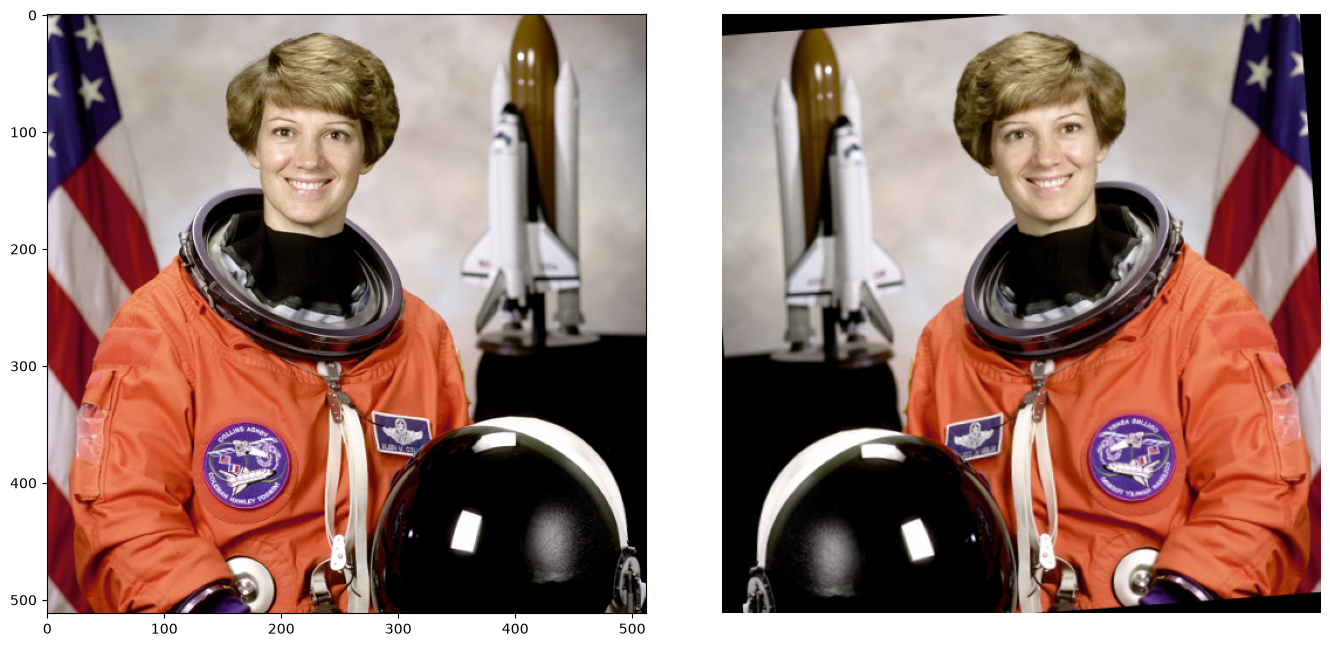

In [89]:
import albumentations as A

pipeline = A.Compose([
  A.HorizontalFlip(p=0.5),
  A.Rotate(limit=20, p=0.7),
  A.RandomBrightnessContrast(p=0.3),
  A.GaussianBlur(blur_limit=(3,5), p=0.2)
])

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
axes[0].imshow(astronauta)
augmented = pipeline(image=astronauta)["image"]
axes[1].imshow(augmented)
plt.axis("off")
plt.tight_layout()
plt.show()

In [82]:
def cosine_similarity(a, b):
  return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

flipped = astronauta[:, ::-1]
lower = np.clip(astronauta.astype(np.int16) - 50, 0, 255).astype(np.uint8)
moved = np.roll(astronauta, 20, axis=1)

from skimage import transform

coffee = transform.resize(data.coffee(), (512,512))

astronauta = astronauta.astype(np.float32).flatten() 

flipped = flipped.astype(np.float32).flatten() 
lower = lower.astype(np.float32).flatten()
moved = moved.astype(np.float32).flatten() 
coffee = coffee.astype(np.float32).flatten() 

print(cosine_similarity(astronauta, flipped))
print(cosine_similarity(astronauta, lower))
print(cosine_similarity(astronauta, moved))
print(cosine_similarity(astronauta, coffee))

0.6922357
0.9883103
0.8552011
0.732585
